**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
%pip -q install kagglehub imbalanced-learn xgboost lightgbm catboost

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("Папка датасету:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Папка датасету: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [4]:
df.info()
print("gender і smoking_history — категоріальні ознаки, решта — числові.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
gender і smoking_history — категоріальні ознаки, решта — числові.


Провести дослідження категоріальних ознак

In [5]:
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [6]:
print(df['smoking_history'].value_counts())
print('No Info — окрема категорія: інформацію про куріння не вказано.')

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64
No Info — окрема категорія: інформацію про куріння не вказано.


In [7]:
print(df.head())

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  


Вивести типи даних

In [8]:
print(df.dtypes)

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [9]:
print(df['diabetes'].value_counts())
print(f"Частка класу 1: {df['diabetes'].mean():.2%}. Класи незбалансовані: клас 0 переважає.")

diabetes
0    91500
1     8500
Name: count, dtype: int64
Частка класу 1: 8.50%. Класи незбалансовані: клас 0 переважає.


**Висновок:** клас 0 переважає. Тому, крім accuracy, оцінюємо F1 та recall класу 1; для навчання використовуємо SMOTE.

Перевірити наявність пропущених даних


In [10]:
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [11]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
print(df.head())
print("Розмір після видалення дублікатів:", df.shape)

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
Розмір після видалення дублікатів: (96146, 9)


Ще раз перевірити баланс цільової змінної

In [14]:
print(df['diabetes'].value_counts())

diabetes
0    87664
1     8482
Name: count, dtype: int64


Побудувати гістограму для цільової змінної


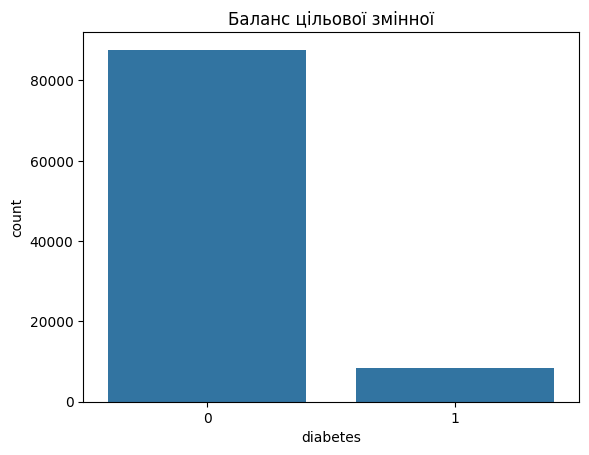

In [15]:
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Баланс цільової змінної')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:
X = df.drop(columns='diabetes')
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [19]:
print(X_train.describe())

                age  hypertension  heart_disease           bmi   HbA1c_level  \
count  76916.000000  76916.000000   76916.000000  76916.000000  76916.000000   
mean      41.760982      0.078007       0.040876     27.313739      5.530527   
std       22.467762      0.268185       0.198004      6.757207      1.072421   
min        0.080000      0.000000       0.000000     10.010000      3.500000   
25%       24.000000      0.000000       0.000000     23.390000      4.800000   
50%       43.000000      0.000000       0.000000     27.320000      5.800000   
75%       59.000000      0.000000       0.000000     29.850000      6.200000   
max       80.000000      1.000000       1.000000     95.220000      9.000000   

       blood_glucose_level  gender_Female   gender_Male  gender_Other  \
count         76916.000000   76916.000000  76916.000000  76916.000000   
mean            138.114281       0.582675      0.417143      0.000182   
std              40.896909       0.493121      0.493090     

Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
target_corr = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
print(target_corr)

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_No Info       -0.113053
smoking_history_former         0.096162
gender_Male                    0.040650
gender_Female                 -0.040533
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
dtype: float64


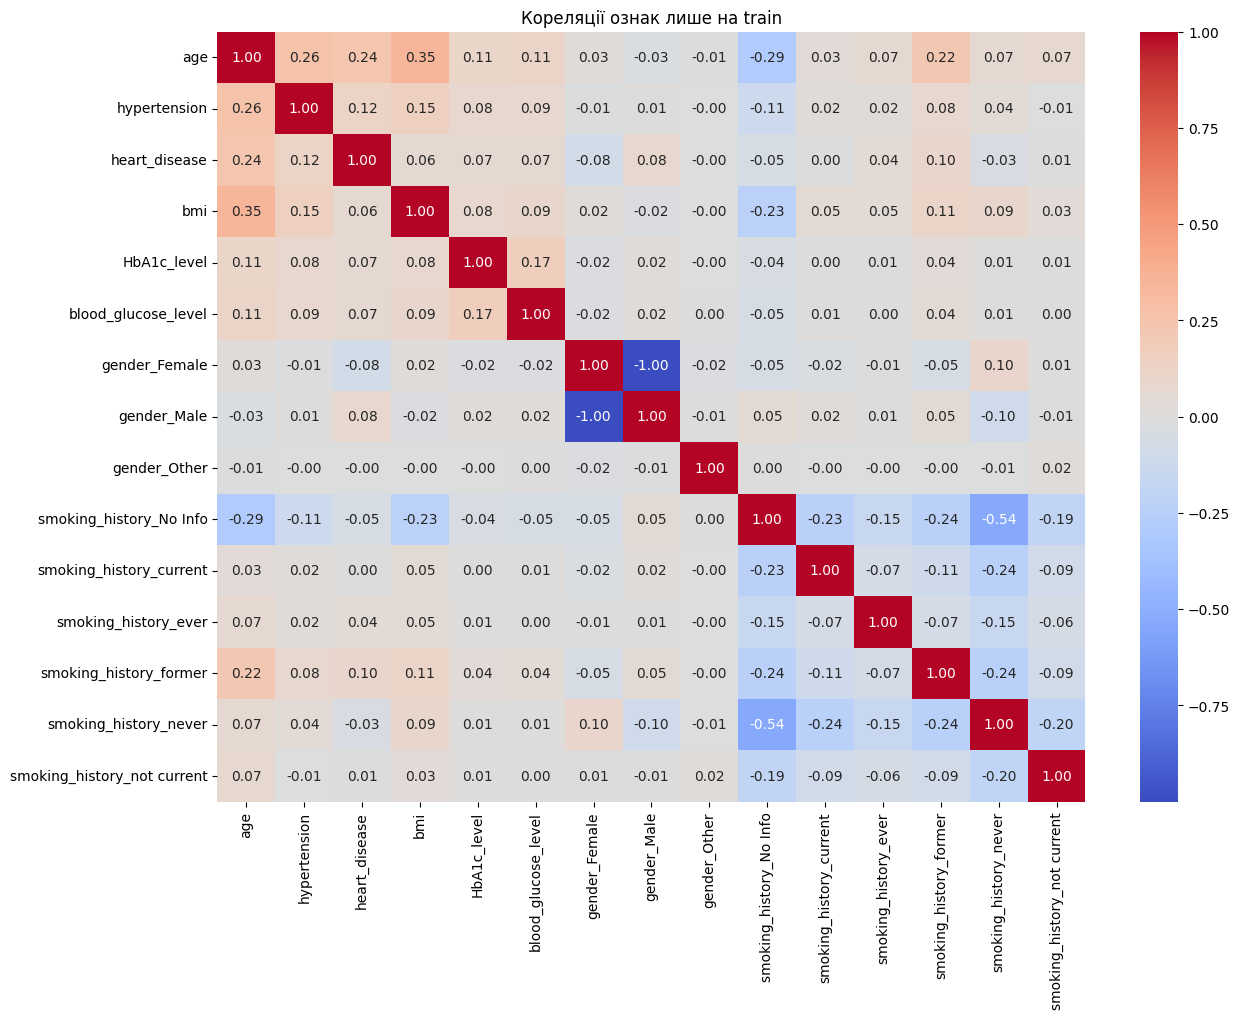

Найбільші за модулем кореляції з ціллю:
blood_glucose_level    0.423011
HbA1c_level            0.405321
age                    0.266649
dtype: float64
Пари ознак із |r| ≥ 0.7:
gender_Female  gender_Male   -0.999626
dtype: float64
Ознаки залишаємо: сама кореляція не доводить, що ознака зайва. Використовуємо регуляризацію.


In [21]:
corr = X_train.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Кореляції ознак лише на train')
plt.show()

strong_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strong_pairs = strong_pairs[strong_pairs.abs() >= 0.7]
print('Найбільші за модулем кореляції з ціллю:')
print(target_corr.head(3))
print('Пари ознак із |r| ≥ 0.7:')
print(strong_pairs)
print('Ознаки залишаємо: сама кореляція не доводить, що ознака зайва. Використовуємо регуляризацію.')

Перевірити викиди **лише на навчальній вибірці**

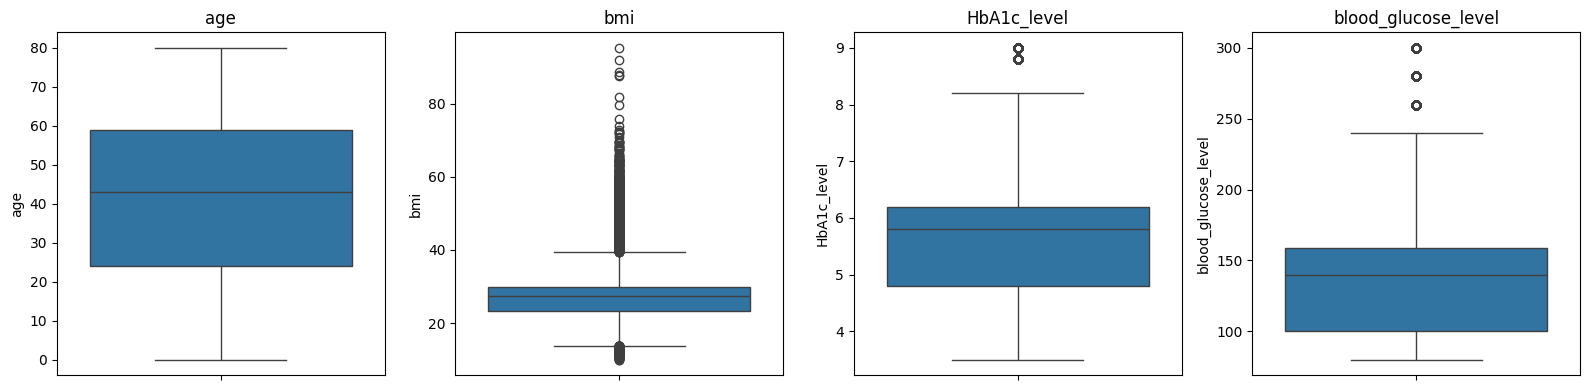

age                       0
bmi                    4244
HbA1c_level            1041
blood_glucose_level    1598
Name: Кількість значень за межами IQR, dtype: int64


In [22]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, ax in zip(continuous_cols, axes):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Q1 = X_train[continuous_cols].quantile(0.25)
Q3 = X_train[continuous_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((X_train[continuous_cols] < Q1 - 1.5 * IQR) |
                  (X_train[continuous_cols] > Q3 + 1.5 * IQR)).sum()
print(outlier_counts.rename('Кількість значень за межами IQR'))

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# Приклад лише в коментарях — рядки не видаляємо.
# q1 = X_train['bmi'].quantile(0.25)
# q3 = X_train['bmi'].quantile(0.75)
# iqr = q3 - q1
# mask = X_train['bmi'].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
# X_train = X_train.loc[mask]
# y_train = y_train.loc[mask]
# X_test та y_test залишаються незмінними.

Перевірити асиметрію розподілів ознак **на train**

In [23]:
print(X_train[continuous_cols].skew().rename('Асиметрія'))

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
Name: Асиметрія, dtype: float64


In [24]:
print(pd.DataFrame({'train': X_train.isnull().sum(), 'test': X_test.isnull().sum()}))

                             train  test
age                              0     0
hypertension                     0     0
heart_disease                    0     0
bmi                              0     0
HbA1c_level                      0     0
blood_glucose_level              0     0
gender_Female                    0     0
gender_Male                      0     0
gender_Other                     0     0
smoking_history_No Info          0     0
smoking_history_current          0     0
smoking_history_ever             0     0
smoking_history_former           0     0
smoking_history_never            0     0
smoking_history_not current      0     0


**Проміжний висновок:** класи незбалансовані. Кореляції, асиметрію і межі IQR обчислено лише за train; їхні значення наведено вище. Значення за межами IQR не обов’язково є помилками, тому їх залишаємо. Тестову вибірку не скорочуємо і не балансуємо.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [26]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)
print(pd.DataFrame({'До SMOTE': y_train.value_counts(),
                      'Після SMOTE': y_train_balanced.value_counts()}))

          До SMOTE  Після SMOTE
diabetes                       
0            70130        70130
1             6786        70130


Оголошуємо моделі

In [27]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(max_iter=2000, random_state=42),
    'SVC': SVC(random_state=42, cache_size=512)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


Навчання: LogisticRegression
LogisticRegression
              precision    recall  f1-score   support

           0      0.987     0.885     0.933     17534
           1      0.426     0.879     0.574      1696

    accuracy                          0.885     19230
   macro avg      0.706     0.882     0.754     19230
weighted avg      0.937     0.885     0.902     19230



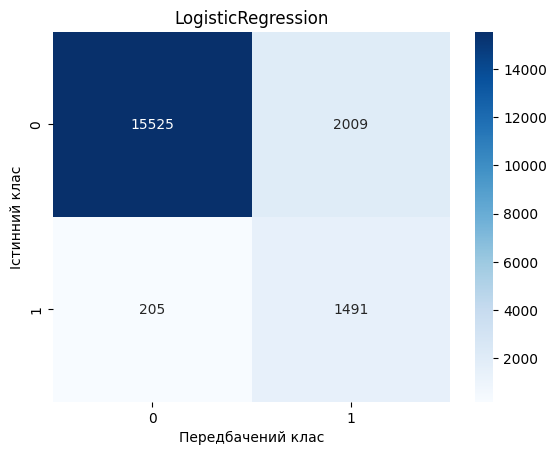

Навчання: RidgeClassifier
RidgeClassifier
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.432     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.709     0.882     0.757     19230
weighted avg      0.938     0.888     0.904     19230



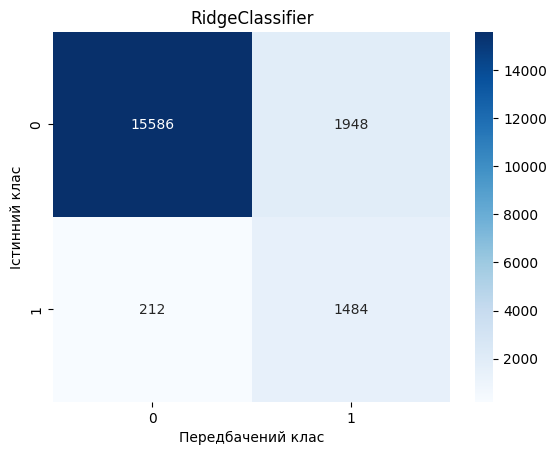

Навчання: SGDClassifier
SGDClassifier
              precision    recall  f1-score   support

           0      0.990     0.856     0.918     17534
           1      0.379     0.909     0.535      1696

    accuracy                          0.861     19230
   macro avg      0.684     0.882     0.726     19230
weighted avg      0.936     0.861     0.884     19230



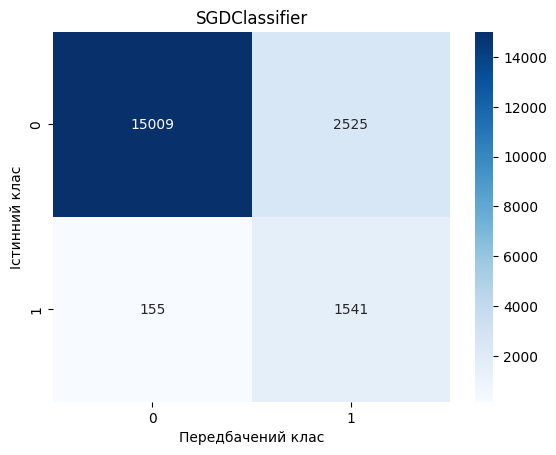

Навчання: SVC
SVC
              precision    recall  f1-score   support

           0      0.990     0.881     0.933     17534
           1      0.425     0.907     0.579      1696

    accuracy                          0.884     19230
   macro avg      0.708     0.894     0.756     19230
weighted avg      0.940     0.884     0.901     19230



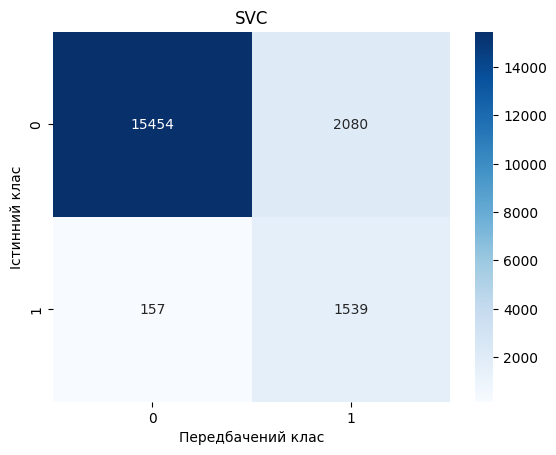

                    F1 (клас 1)  Recall (клас 1)
LogisticRegression     0.573903         0.879127
RidgeClassifier        0.578783         0.875000
SGDClassifier          0.534884         0.908608
SVC                    0.579116         0.907429


In [28]:
def evaluate(name, model, X_eval):
    pred = model.predict(X_eval)
    print(name)
    print(classification_report(y_test, pred, digits=3, zero_division=0))
    sns.heatmap(confusion_matrix(y_test, pred, labels=[0, 1]), annot=True,
                fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
    plt.title(name)
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()
    report = classification_report(y_test, pred, output_dict=True, zero_division=0)
    return {'F1 (клас 1)': report['1']['f1-score'],
            'Recall (клас 1)': report['1']['recall']}

base_results = {}
for name, model in models.items():
    print('Навчання:', name, flush=True)
    model.fit(X_train_balanced, y_train_balanced)
    base_results[name] = evaluate(name, model, X_test_scaled)
print(pd.DataFrame(base_results).T)

Оптимізувати гіперпараметри


In [29]:
param_grids = {
    'LogisticRegression': {'model__C': [0.1, 1, 10], 'model__solver': ['lbfgs', 'liblinear']},
    'RidgeClassifier': {'model__alpha': [0.1, 1, 10]},
    'SGDClassifier': {'model__loss': ['hinge', 'log_loss'], 'model__penalty': ['l2', 'l1']},
    'SVC': {'model__C': [0.1, 1, 10], 'model__kernel': ['linear', 'rbf']}
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [30]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

Підбір параметрів: LogisticRegression
Оптимальні параметри: {'model__C': 10, 'model__solver': 'lbfgs'}
Середній F1 на CV: 0.6153
LogisticRegression після підбору
              precision    recall  f1-score   support

           0      0.987     0.886     0.933     17534
           1      0.425     0.875     0.572      1696

    accuracy                          0.885     19230
   macro avg      0.706     0.880     0.753     19230
weighted avg      0.937     0.885     0.902     19230



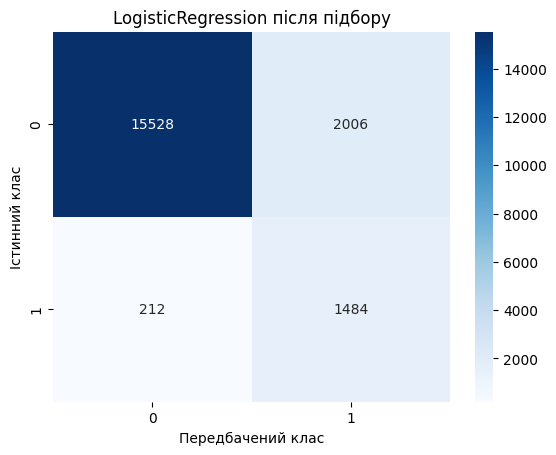

Підбір параметрів: RidgeClassifier
Оптимальні параметри: {'model__alpha': 10}
Середній F1 на CV: 0.654
RidgeClassifier після підбору
              precision    recall  f1-score   support

           0      0.986     0.891     0.936     17534
           1      0.437     0.873     0.583      1696

    accuracy                          0.890     19230
   macro avg      0.712     0.882     0.760     19230
weighted avg      0.938     0.890     0.905     19230



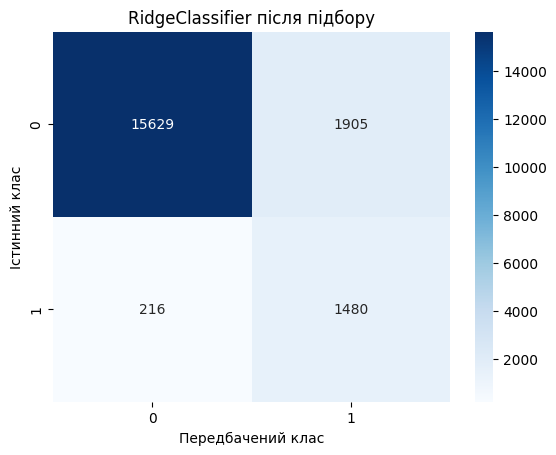

Підбір параметрів: SGDClassifier
Оптимальні параметри: {'model__loss': 'log_loss', 'model__penalty': 'l1'}
Середній F1 на CV: 0.5818
SGDClassifier після підбору
              precision    recall  f1-score   support

           0      0.986     0.890     0.936     17534
           1      0.434     0.869     0.578      1696

    accuracy                          0.888     19230
   macro avg      0.710     0.879     0.757     19230
weighted avg      0.937     0.888     0.904     19230



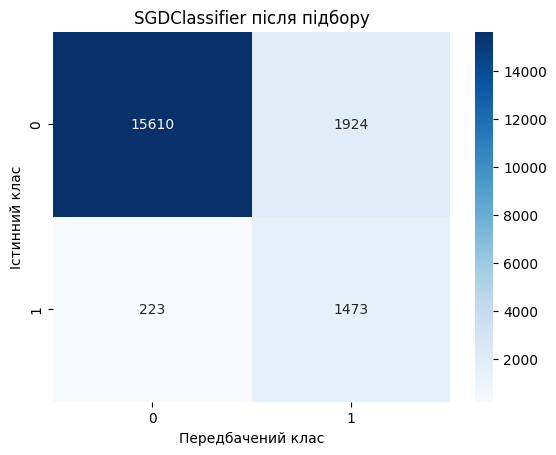

Підбір параметрів: SVC
Оптимальні параметри: {'model__C': 1, 'model__kernel': 'linear'}
Середній F1 на CV: 0.6186
SVC після підбору
              precision    recall  f1-score   support

           0      0.987     0.883     0.932     17534
           1      0.422     0.883     0.571      1696

    accuracy                          0.883     19230
   macro avg      0.705     0.883     0.752     19230
weighted avg      0.937     0.883     0.900     19230



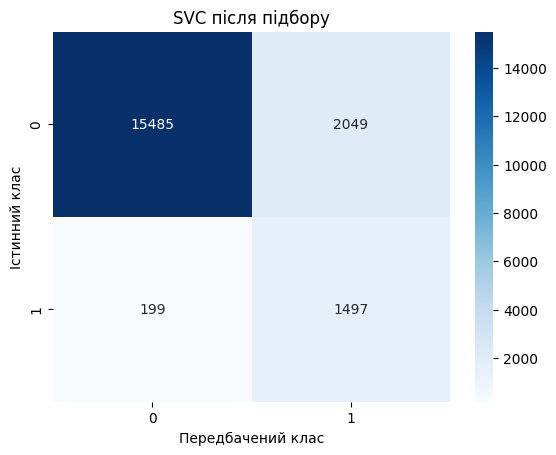

                    F1 (клас 1)  Recall (клас 1)
LogisticRegression     0.572310         0.875000
RidgeClassifier        0.582562         0.872642
SGDClassifier          0.578441         0.868514
SVC                    0.571156         0.882665


In [31]:
best_models = {}
best_scores = {}
best_params = {}
tuned_results = {}
for name, model in models.items():
    print('Підбір параметрів:', name, flush=True)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, k_neighbors=1)),
        ('model', model)
    ])
    # Один сусід SMOTE потрібен для малих навчальних частин пошуку.
    search = HalvingGridSearchCV(
        pipeline, param_grids[name], cv=3, scoring='f1',
        min_resources=300, factor=3, random_state=42, n_jobs=1,
        error_score='raise'
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    best_params[name] = search.best_params_
    print('Оптимальні параметри:', search.best_params_)
    print('Середній F1 на CV:', round(search.best_score_, 4))
    tuned_results[name] = evaluate(name + ' після підбору', search.best_estimator_, X_test)
print(pd.DataFrame(tuned_results).T)

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [32]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print('Найкраща модель за CV:', best_name)
print('Середній F1 на CV:', round(best_scores[best_name], 4))
print(pd.Series(best_scores, name='F1 на CV').sort_values(ascending=False))

Найкраща модель за CV: RidgeClassifier
Середній F1 на CV: 0.654
RidgeClassifier       0.654002
SVC                   0.618629
LogisticRegression    0.615261
SGDClassifier         0.581788
Name: F1 на CV, dtype: float64


In [33]:
sample = X_test.sample(n=10, random_state=42)
print(pd.DataFrame({
    'індекс': sample.index,
    'істинний клас': y_test.loc[sample.index].to_numpy(),
    'передбачений клас': best_model.predict(sample)
}))

   індекс  істинний клас  передбачений клас
0   36061              0                  0
1   29824              0                  0
2   29668              0                  1
3   11816              0                  0
4   99242              0                  0
5   26718              0                  0
6   53059              0                  0
7   69294              0                  0
8    8912              0                  1
9   37072              0                  0


**Підсумкові висновки**

Числові відповіді на пункти 1–3 формуються в наступній клітинці за результатами запуску.

4. Тестові дані відкладаємо для незалежної оцінки. Масштабування та SMOTE навчаються лише на train, а під час пошуку — всередині кожного навчального згину. Інакше інформація з перевірочних даних потрапить у навчання й оцінка буде завищеною. Test зберігає початковий баланс класів.

Пошук із min_resources=300 порівнює кандидатів на невеликих підвибірках, тому CV-оцінка може бути нестійкою. Переможець кожного пошуку автоматично перенавчається на всій навчальній вибірці.

In [34]:
print(f"1. Частка diabetes=1 на train: {y_train.mean():.2%}.")
print('Найсильніші кореляції з ціллю:', target_corr.head(3).round(3).to_dict())
print('Кількість викидів за IQR:', outlier_counts.to_dict(), 'Їх не видаляли.')
comparison = pd.concat({'До підбору': pd.DataFrame(base_results).T,
                        'Після підбору': pd.DataFrame(tuned_results).T})
print(comparison)
print('2. Найбільший тестовий F1:', comparison['F1 (клас 1)'].idxmax())
print('Найбільший тестовий recall:', comparison['Recall (клас 1)'].idxmax())
print(f'Обрана лише за CV модель: {best_name}, F1 CV = {best_scores[best_name]:.3f}.')
print('3. Оптимальні параметри кожної моделі:')
for name, params in best_params.items():
    print(name, params)
tn, fp, fn, tp = confusion_matrix(y_test, best_model.predict(X_test), labels=[0, 1]).ravel()
print(f'Для обраної моделі: TN={tn}, FP={fp}, FN={fn}, TP={tp}.')
print('FP — помилково передбачений діабет; FN — пропущений випадок діабету.')

1. Частка diabetes=1 на train: 8.82%.
Найсильніші кореляції з ціллю: {'blood_glucose_level': 0.423, 'HbA1c_level': 0.405, 'age': 0.267}
Кількість викидів за IQR: {'age': 0, 'bmi': 4244, 'HbA1c_level': 1041, 'blood_glucose_level': 1598} Їх не видаляли.
                                  F1 (клас 1)  Recall (клас 1)
До підбору    LogisticRegression     0.573903         0.879127
              RidgeClassifier        0.578783         0.875000
              SGDClassifier          0.534884         0.908608
              SVC                    0.579116         0.907429
Після підбору LogisticRegression     0.572310         0.875000
              RidgeClassifier        0.582562         0.872642
              SGDClassifier          0.578441         0.868514
              SVC                    0.571156         0.882665
2. Найбільший тестовий F1: ('Після підбору', 'RidgeClassifier')
Найбільший тестовий recall: ('До підбору', 'SGDClassifier')
Обрана лише за CV модель: RidgeClassifier, F1 CV = 0.654.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

XGBoost
              precision    recall  f1-score   support

           0      0.975     0.988     0.982     17534
           1      0.856     0.742     0.795      1696

    accuracy                          0.966     19230
   macro avg      0.916     0.865     0.888     19230
weighted avg      0.965     0.966     0.965     19230



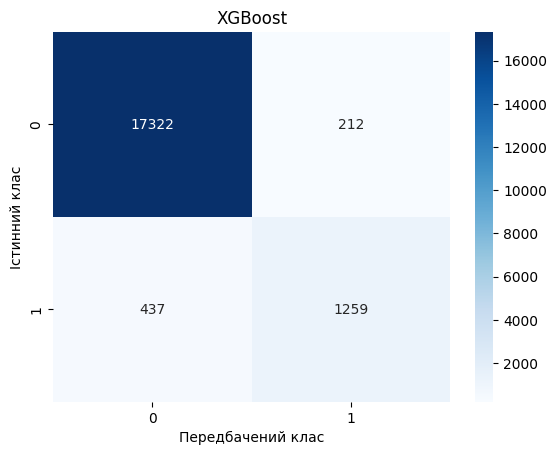

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM
              precision    recall  f1-score   support

           0      0.972     0.996     0.984     17534
           1      0.941     0.708     0.808      1696

    accuracy                          0.970     19230
   macro avg      0.957     0.852     0.896     19230
weighted avg      0.970     0.970     0.968     19230



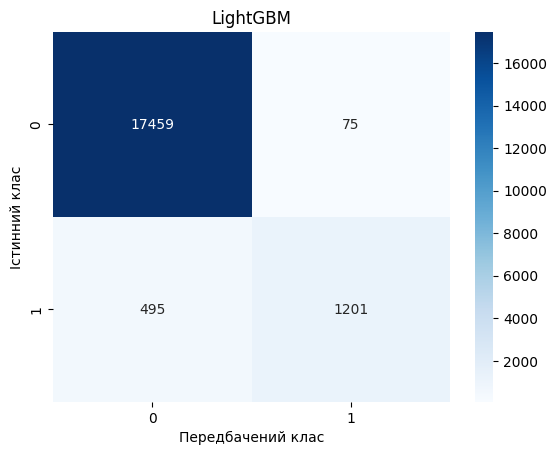

CatBoost
              precision    recall  f1-score   support

           0      0.979     0.973     0.976     17534
           1      0.739     0.781     0.759      1696

    accuracy                          0.956     19230
   macro avg      0.859     0.877     0.868     19230
weighted avg      0.958     0.956     0.957     19230



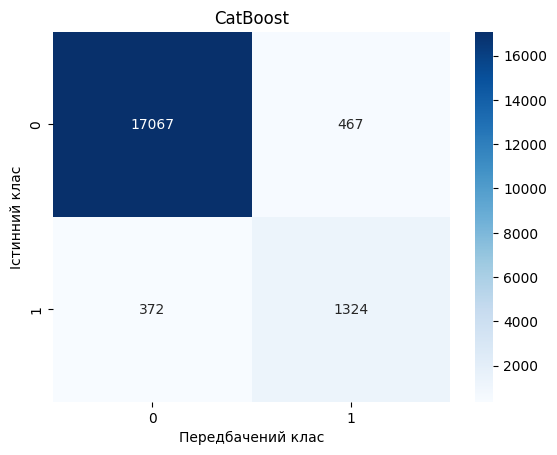

          F1 (клас 1)  Recall (клас 1)
XGBoost      0.795074         0.742335
LightGBM     0.808210         0.708137
CatBoost     0.759392         0.780660
Висновок: серед додаткових моделей найбільший F1 має LightGBM
Найбільший recall має CatBoost
F1 враховує точність позитивних прогнозів і повноту, recall — частку виявлених випадків діабету.
Це порівняння на test; основну модель вище обрано за CV.


In [35]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

extra_models = {
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                             eval_metric='logloss', random_state=42, n_jobs=2),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=42, verbosity=-1, n_jobs=2),
    'CatBoost': CatBoostClassifier(iterations=100, depth=5, learning_rate=0.1,
                                   random_seed=42, verbose=False, thread_count=2,
                                   allow_writing_files=False)
}
extra_results = {}
for name, model in extra_models.items():
    model.fit(X_train_balanced, y_train_balanced)
    extra_results[name] = evaluate(name, model, X_test_scaled)

extra_table = pd.DataFrame(extra_results).T
print(extra_table)
print('Висновок: серед додаткових моделей найбільший F1 має', extra_table['F1 (клас 1)'].idxmax())
print('Найбільший recall має', extra_table['Recall (клас 1)'].idxmax())
print('F1 враховує точність позитивних прогнозів і повноту, recall — частку виявлених випадків діабету.')
print('Це порівняння на test; основну модель вище обрано за CV.')